<div style="background:rgba(128,128,128,0.05);border:1px solid rgba(128,128,128,0.26);color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));border-radius:12px;padding:28px 30px;"><div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#8B5CF6;">Qiskit Fall Fest Connecticut 2026 &nbsp;·&nbsp; qBraid challenge &nbsp;·&nbsp; Starter notebook</span></div><div style="margin:0 0 14px 0;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:12px;letter-spacing:1px;color:rgba(128,128,128,0.98);white-space:nowrap;"><svg width="12" height="12" viewBox="0 0 24 24" fill="none" stroke="rgba(128,128,128,0.98)" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>about 65 minutes end to end</span></div><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:38px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">Solve <span style="color:#8B5CF6;">Instant Insanity</span> with a quantum computer</div><p style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:16px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 13px 0;">You get four cubes. Each face is painted one of four colours. Stack the cubes in a tower so that every colour shows exactly once on each of the four sides. The puzzle looks small, but most people give up before they find the one answer by hand.</p><p style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:16px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 13px 0;">Puzzles like this are <b>constraint problems</b>: many choices, a few rules, and very few choices that obey every rule. Scheduling, routing and chip layout all have the same shape. Quantum optimization algorithms attack them by turning the rules into an energy and searching for the lowest one. This notebook walks you from the puzzle to a first quantum run. The path:</p><ol style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:15px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 13px 0;padding-left:22px;"><li style="margin:0 0 9px 0;"><b style="font-weight:600;">What the puzzle asks.</b> <span style="color:rgba(128,128,128,0.98);">The four cubes, drawn flat, and what a solved tower looks like.</span></li><li style="margin:0 0 9px 0;"><b style="font-weight:600;">How many towers there are.</b> <span style="color:rgba(128,128,128,0.98);">A classical brute force over every tower, so you know how many answers to expect.</span></li><li style="margin:0 0 9px 0;"><b style="font-weight:600;">The graph trick.</b> <span style="color:rgba(128,128,128,0.98);">The classic idea that turns the puzzle into a question about a small graph, used to solve the front and back.</span></li><li style="margin:0 0 9px 0;"><b style="font-weight:600;">The puzzle as a cost function.</b> <span style="color:rgba(128,128,128,0.98);">Rules become penalties, and the answer becomes the lowest score.</span></li><li style="margin:0 0 9px 0;"><b style="font-weight:600;">From a cost function to qubits.</b> <span style="color:rgba(128,128,128,0.98);">The same score, written as a Hamiltonian a quantum computer can use.</span></li><li style="margin:0 0 9px 0;"><b style="font-weight:600;">A first quantum run.</b> <span style="color:rgba(128,128,128,0.98);">QAOA on half of the puzzle, locally and then on the AWS SV1 simulator, with a qBraid job you submit yourself.</span></li><li style="margin:0 0 9px 0;"><b style="font-weight:600;">Your challenge.</b> <span style="color:rgba(128,128,128,0.98);">Add the left and right, and solve the whole puzzle with a quantum algorithm. Then the bonus: N cubes and N colours.</span></li></ol><p style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:16px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 13px 0;">New to Qiskit or qBraid? The <code>resources/</code> folder has three short notebooks: a Qiskit refresher, a qBraid SDK tour, and QAOA for MaxCut on SV1.</p></div>

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#8B5CF6;">Before you start</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#8B5CF6;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#8B5CF6" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

Run the two cells below: the first installs anything missing, the second loads the imports.

Drawing code and other plumbing live in `resources/helpers.py`, so this notebook keeps only the puzzle and the algorithm. Each cell imports the helpers it needs. Keep the notebook in the top folder of the repo, next to `resources/`, or the imports fail.

In [1]:
import importlib.util
import subprocess
import sys

# install only what is missing; upgrading an already-imported package can break it
NEEDED = {"qiskit": "qiskit>=1.3,<3", "qiskit_aer": "qiskit-aer>=0.15",
          "qbraid": "qbraid[qiskit]>=0.12", "matplotlib": "matplotlib",
          "networkx": "networkx", "scipy": "scipy", "pylatexenc": "pylatexenc"}
missing = [spec for mod, spec in NEEDED.items()
           if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing],
                   check=True)
print("installed:", ", ".join(missing) or "nothing, everything was already here")

installed: qiskit>=1.3,<3, qiskit-aer>=0.15, qbraid[qiskit]>=0.12, pylatexenc


In [2]:
import itertools
import time

import numpy as np

from resources.helpers import SEED

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#8B5CF6;">Section 1 · The puzzle</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#8B5CF6;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#8B5CF6" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">What does a <span style="color:#8B5CF6;">solved tower</span> look like?</div>

A cube has six faces in three **opposite pairs**: front and back, left and right, top and bottom. That pairing is the key to the whole puzzle. When a cube sits in the tower, one pair faces front and back, one pair faces left and right, and the third pair hides on the top and bottom.

So the cell below stores each cube as its three opposite pairs. The letters are the colours: <b>R</b>ed, <b>G</b>reen, <b>B</b>lue and <b>Y</b>ellow. The string `"GR"` means one face is green and the face opposite it is red.

In [3]:
COLOURS = "RGBY"

CUBES = [
    ["GR", "BR", "GY"],   # cube 1
    ["GY", "RB", "BY"],   # cube 2
    ["BR", "RG", "RY"],   # cube 3
    ["YR", "RG", "BG"],   # cube 4
]

A cube is easier to read unfolded, as a flat cross of six squares. Fold the cross back up and the middle square is the front. The far right square folds round to the back. The two arms become the left and right sides, and the squares above and below become the top and bottom. So opposite faces always sit two squares apart in the cross.

Here is cube 1 both ways: flat, with each face named, and as a solid cube seen from the front and from behind. Match each square of the cross to its face on the solid cube.

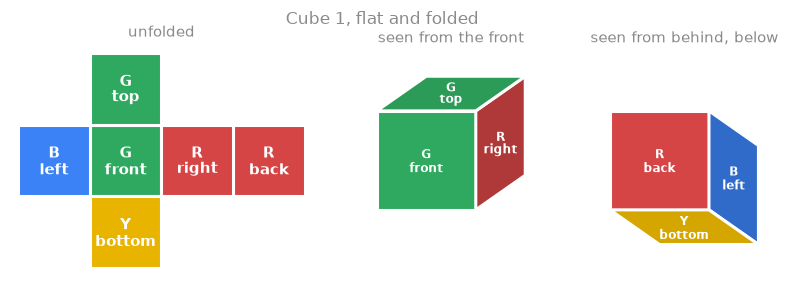

The same cross works for every cube. `draw_nets` draws all four flat. Before you run it, count the red faces on each cube. Which cube has the most?

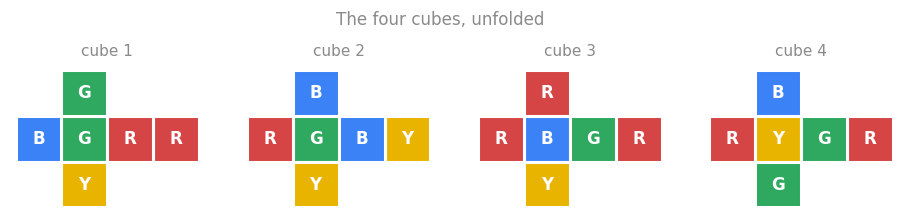

In [4]:
from resources.helpers import draw_nets

draw_nets(CUBES)

Cube 3 has three red faces, so red is the colour to place with care. A tower shows four faces of each cube, one per side. A solved tower shows four different colours on every side, so each side reads R, G, B and Y in some order.

How do you search for one? Section 2 starts with the method that never fails: try every tower.

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#8B5CF6;">Section 2 · Brute force</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#8B5CF6;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#8B5CF6" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">How many towers are there, and <span style="color:#8B5CF6;">how many work</span>?</div>

A cube can sit in **24 orientations**. You choose which pair faces front and back (3 ways), which of the other two faces left and right (2 ways), which colour of the first pair faces the front (2 ways), and which colour of the second pair faces right (2 ways): $3 \times 2 \times 2 \times 2 = 24$.

Four cubes give $24^4 = 331{,}776$ towers. That is far too many to try by hand and very few for a laptop. The helper below lists the 24 orientations as four visible colours, then checks every tower.

In [5]:
def orientations(cube):
    """The 24 ways a cube can sit, as (front, back, left, right) colours."""
    views = []
    for a, b in itertools.permutations(range(3), 2):   # front/back pair, left/right pair
        for fa in (0, 1):
            for fb in (0, 1):
                fb_pair, lr_pair = cube[a], cube[b]
                views.append((fb_pair[fa], fb_pair[1 - fa], lr_pair[fb], lr_pair[1 - fb]))
    return views


def solves(tower):
    """True when each of the four sides shows four different colours."""
    return all(len({view[side] for view in tower}) == len(tower) for side in range(4))


start = time.perf_counter()
options = [orientations(cube) for cube in CUBES]
winners = [tower for tower in itertools.product(*options) if solves(tower)]
seconds = time.perf_counter() - start
print(f"checked {24 ** len(CUBES):,} towers in {seconds:.1f} s, found {len(winners)} solutions")

checked 331,776 towers in 0.3 s, found 8 solutions


Only 8 towers out of 331,776 work, about 1 in 41,000. They are all the same tower: turn a solved tower a quarter turn, or flip it upside down, and it is still solved. Those are $4 \times 2 = 8$ views of one answer.

<div style="background:rgba(128,128,128,0.08);border:1px solid rgba(128,128,128,0.26);border-radius:10px;padding:18px 22px;margin:14px 0;"><div style="display:flex;gap:26px;flex-wrap:wrap;"><div style="flex:1;min-width:120px;"><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:30px;color:#8B5CF6;line-height:1.1;">331,776</div><div style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:10.5px;letter-spacing:1px;text-transform:uppercase;color:rgba(128,128,128,0.98);margin-top:6px;">towers</div></div><div style="flex:1;min-width:120px;"><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:30px;color:#8B5CF6;line-height:1.1;">8</div><div style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:10.5px;letter-spacing:1px;text-transform:uppercase;color:rgba(128,128,128,0.98);margin-top:6px;">solved towers</div></div><div style="flex:1;min-width:120px;border-left:2px solid #C2772A;padding-left:14px;"><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:34px;color:#C2772A;line-height:1.1;">1</div><div style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:10.5px;letter-spacing:1px;text-transform:uppercase;color:#C2772A;margin-top:6px;">distinct answer</div></div></div><div style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;color:rgba(128,128,128,0.98);line-height:1.6;margin-top:16px;padding-top:12px;border-top:1px solid rgba(128,128,128,0.26);">Exact counts from the brute force above. The 8 solved towers are one tower seen in its 8 symmetric positions.</div></div>

Brute force is fine at four cubes. It is not fine at scale, because every extra cube multiplies the work by 24. The next section cuts the search down with a trick from 1960s puzzle books.

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#8B5CF6;">Section 3 · The graph trick</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#8B5CF6;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#8B5CF6" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>10 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">Why does the puzzle only care about <span style="color:#8B5CF6;">opposite pairs</span>?</div>

Look at the front and back of the tower together. Each cube puts one opposite pair there. Each side must show every colour once, so across the front and the back each colour appears **exactly twice**. The same holds for left and right.

That suggests a picture. Draw a **graph**: one dot per colour, and one line per opposite pair, joining the pair's two colours. Each cube contributes three lines. A pair painted with one colour twice would be a loop; this puzzle has none.

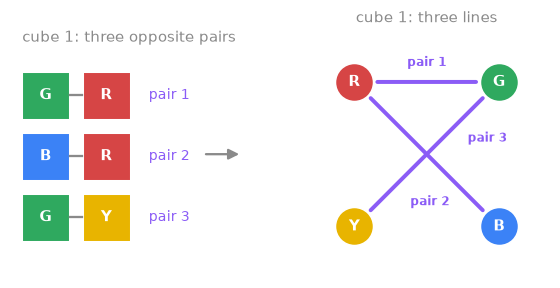

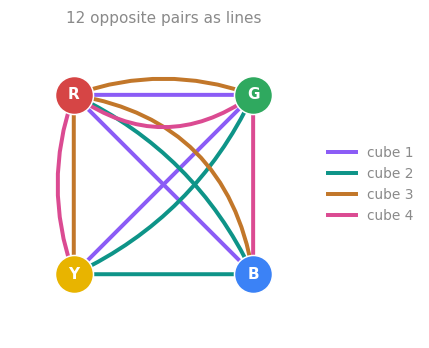

In [6]:
from resources.helpers import draw_graph

draw_graph(CUBES, title="12 opposite pairs as lines")

Now restate the rule for the front and back. Pick **one line per cube** so that every dot touches exactly two picked lines. In graph language, the picked lines form a **2-factor**: a set of lines that meets every dot exactly twice. The left and right need a second 2-factor, and each cube must use a **different** line for it, because one pair cannot face two directions at once.

The example below uses made-up cubes, not this puzzle's. On the left, the picked lines form one loop. Walking it gives each cube a front and a back, and each side shows every colour once. On the right, red is touched three times, so red would show twice on one side.

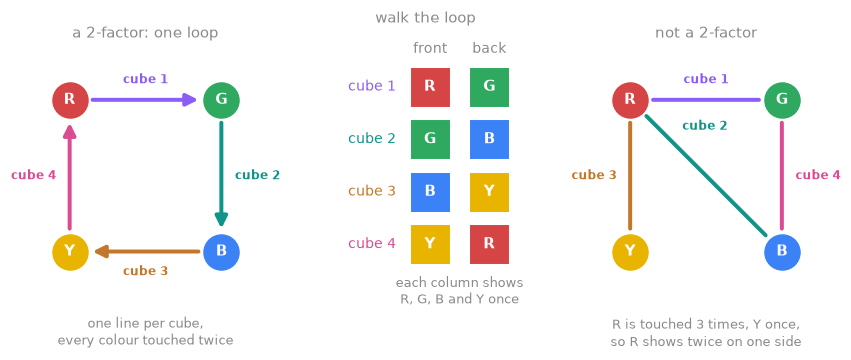

So the whole puzzle becomes: find two 2-factors that never pick the same line of a cube. Each cube then has only $3 \times 2 = 6$ choices, so four cubes give $6^4 = 1{,}296$ cases instead of 331,776.

This notebook solves the first half: the front and back. That needs one 2-factor, one line per cube out of three, so $3^4 = 81$ cases. The cell below checks them all. `CHOICES` lists the 6 choices per cube for the full puzzle, which you will need later.

<details style="background:rgba(128,128,128,0.08);border:1px solid rgba(128,128,128,0.26);border-left:2px solid #8B5CF6;border-radius:10px;padding:12px 18px;margin:16px 0;"><summary style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:400;font-size:14px;color:#8B5CF6;cursor:pointer;">Background &nbsp;&middot;&nbsp; why two 2-factors are enough<span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1.4px;text-transform:uppercase;color:rgba(128,128,128,0.98);margin-left:10px;">click to expand</span></summary>

A 2-factor splits into closed loops of dots, called cycles. Walk around a cycle and put the colour you leave on the front and the colour you arrive at on the back. Every dot is left once and arrived at once, so each colour lands once on the front and once on the back.

The same walk on the second 2-factor sets the left and right. The two 2-factors use different pairs of each cube, so the walk never asks one pair to face two ways. That is why the 6 choices per cube carry all the information, and the four flips per cube follow for free.

</details>

In [7]:
CHOICES = list(itertools.permutations(range(3), 2))  # (front/back pair, left/right pair)


def degrees(cubes, picks):
    """How many picked lines touch each colour."""
    count = dict.fromkeys(COLOURS, 0)
    for cube, p in zip(cubes, picks):
        for colour in cube[p]:
            count[colour] += 1
    return count


def is_two_factor(cubes, picks):
    return all(d == 2 for d in degrees(cubes, picks).values())


front_back = [picks for picks in itertools.product(range(3), repeat=len(CUBES))
              if is_two_factor(CUBES, picks)]
print(f"{len(front_back)} of {3 ** len(CUBES)} front/back picks are 2-factors")

4 of 81 front/back picks are 2-factors


Four picks work. The figure below highlights the first one. It is one closed loop through all four colours, so every dot touches two bold lines.

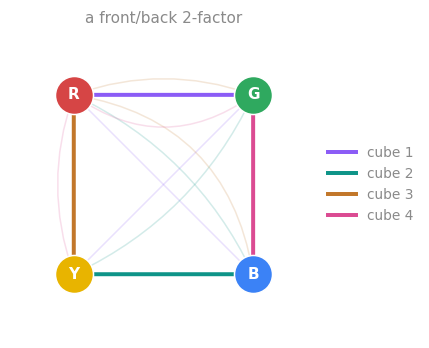

In [8]:
draw_graph(CUBES, front_back[0], "a front/back 2-factor")

`orient` walks the loop, as in the background fold above, and gives each cube a front and a back. `draw_tower` draws the result. The left and right stay blank: they are yours.

The cell also imports `tower_from` for later. It turns a full answer, one (front/back, left/right) choice per cube, into a tower you can check with `solves`.

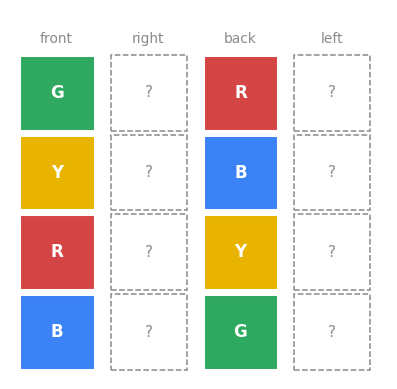

In [9]:
from resources.helpers import draw_tower, orient, tower_from

ends = orient(CUBES, front_back[0])
draw_tower([(ends[c][0], None, ends[c][1], None) for c in range(len(CUBES))])

The front and back columns each hold R, G, B and Y once. Not every front/back pick can be finished, though. The left and right need a second 2-factor that never uses the same line of a cube as the first. Only some of the four picks have such a partner. Finding a complete pair is the challenge.

For four cubes a laptop does not care. For $N$ cubes and $N$ colours the same question is **NP-complete**: no one knows a method that stays fast as $N$ grows. That is the kind of problem quantum optimization research targets, and the next step is to write the rules as a score.

<div style="background:rgba(128,128,128,0.08);border:1px solid rgba(128,128,128,0.26);border-left:2px solid #8B5CF6;border-radius:10px;padding:18px 22px;margin:14px 0;"><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:400;font-size:14px;color:#8B5CF6;margin-bottom:7px;">Reference</div><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:14.5px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));">E. Robertson and I. Munro, "NP-completeness, puzzles and games", Utilitas Mathematica 13 (1978) 99-116, shows that the N-cube version is NP-complete. The graph method appears in <a href="https://en.wikipedia.org/wiki/Instant_Insanity" style="color:#8B5CF6;">the Wikipedia article on Instant Insanity</a>.</div></div>

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#8B5CF6;">Section 4 · A cost function</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#8B5CF6;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#8B5CF6" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">How do the rules become <span style="color:#8B5CF6;">a score</span> to minimize?</div>

Quantum optimization algorithms do not read rules. They read a **cost function**: a formula that gives every candidate a number, where lower is better. The trick is to build the formula so that it is zero for a solution and positive for anything else.

Start with yes-or-no variables. For cube $c$ and pair $p$, let $x_{c,p} = 1$ when that pair faces front and back, and $0$ otherwise. Let $y_{c,p}$ mean the same for left and right. Four cubes, three pairs and two axes give $4 \times 3 \times 2 = 24$ variables. Each rule becomes a penalty that is zero exactly when the rule holds:

<ul style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:15px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 13px 0;padding-left:22px;"><li style="margin:0 0 6px 0;"><b>one pair per axis:</b> each cube picks exactly one front/back pair and one left/right pair,</li><li style="margin:0 0 6px 0;"><b>no double duty:</b> no pair faces both ways,</li><li style="margin:0 0 6px 0;"><b>front/back degrees:</b> each colour appears twice among the front/back pairs, and</li><li style="margin:0 0 6px 0;"><b>left/right degrees:</b> the same for the left/right pairs.</li></ul>

The total cost adds the four penalties. It is zero only for a solved tower.

<details style="background:rgba(128,128,128,0.08);border:1px solid rgba(128,128,128,0.26);border-left:2px solid #8B5CF6;border-radius:10px;padding:12px 18px;margin:16px 0;"><summary style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:400;font-size:14px;color:#8B5CF6;cursor:pointer;">The maths &nbsp;&middot;&nbsp; the formula<span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1.4px;text-transform:uppercase;color:rgba(128,128,128,0.98);margin-left:10px;">click to expand</span></summary>

Let $m_{c,p,k}$ count the faces of colour $k$ in pair $p$ of cube $c$: it is 0, 1 or 2. The front/back degree of colour $k$ is $d_k = \sum_{c,p} m_{c,p,k}\, x_{c,p}$, and $e_k$ is the same sum over $y$.

$$C(x, y) = \lambda \sum_c \Big[\big(\textstyle\sum_p x_{c,p} - 1\big)^2 + \big(\textstyle\sum_p y_{c,p} - 1\big)^2\Big] + \mu \sum_{c,p} x_{c,p}\, y_{c,p} + \sum_k (d_k - 2)^2 + \sum_k (e_k - 2)^2$$

Every term is a square or a product of 0/1 variables, so it is never negative. A formula like this, with only products of at most two variables, is a **QUBO**: a quadratic unconstrained binary optimization. The weights $\lambda$ and $\mu$ set how much a broken rule costs; the code uses $\lambda = \mu = 2$.

</details>

In [10]:
LAMBDA, MU = 2, 2


def cost(cubes, x, y):
    """x[c][p], y[c][p] are 0/1. Zero exactly for a solved tower."""
    total = 0
    for c in range(len(cubes)):
        total += LAMBDA * ((sum(x[c]) - 1) ** 2 + (sum(y[c]) - 1) ** 2)
        total += MU * sum(x[c][p] * y[c][p] for p in range(3))
    for picks in (x, y):
        for k in COLOURS:
            d = sum(cubes[c][p].count(k) * picks[c][p]
                    for c in range(len(cubes)) for p in range(3))
            total += (d - 2) ** 2
    return total


def one_hot(p):
    return [int(i == p) for i in range(3)]


rng = np.random.default_rng(SEED)
x = [one_hot(p) for p in rng.integers(0, 3, len(CUBES))]
y = [one_hot(p) for p in rng.integers(0, 3, len(CUBES))]
print("cost of a random candidate:", cost(CUBES, x, y))

cost of a random candidate: 8


A random candidate scores above zero, as it should. The formula is only useful if a solved tower scores zero and nothing else does. The next cell scores every way to pick one front/back pair and one left/right pair per cube, $3^4 \times 3^4 = 6{,}561$ candidates, and draws how many land on each score. Predict first: how many candidates score zero?

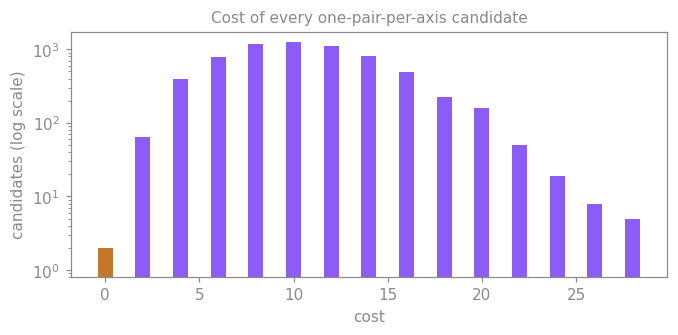

6,561 candidates, 2 at cost 0, lowest nonzero cost 2


In [11]:
from resources.helpers import plot_cost_counts

scores = []
for fb in itertools.product(range(3), repeat=len(CUBES)):
    for lr in itertools.product(range(3), repeat=len(CUBES)):
        scores.append(cost(CUBES, [one_hot(p) for p in fb], [one_hot(p) for p in lr]))
scores = np.array(scores)

plot_cost_counts(scores)
values = np.unique(scores)
print(f"{len(scores):,} candidates, {np.sum(scores == 0)} at cost 0, lowest nonzero cost {values[1]}")

Exactly 2 candidates score zero: the answer and its quarter turn. Everything else costs at least 2. This check matters more than any quantum run. If a wrong tower scored zero, every algorithm would happily return it.

<div style="background:rgba(128,128,128,0.08);border:1px solid rgba(128,128,128,0.26);border-left:2px solid #C2772A;border-radius:10px;padding:18px 22px;margin:14px 0;"><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:400;font-size:14px;color:#C2772A;margin-bottom:7px;">Check your own model the same way</div><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:14.5px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));">Whatever encoding you design for the challenge, first confirm classically that the known answer has the lowest cost and that nothing wrong ties with it. It takes seconds and saves hours.</div></div>

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#8B5CF6;">Section 5 · From cost to qubits</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#8B5CF6;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#8B5CF6" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">How does a quantum computer <span style="color:#8B5CF6;">read a cost function</span>?</div>

Give each variable a qubit. A qubit measured as 1 means the variable is 1. Then rewrite the cost with the **Pauli Z** operator, which returns $+1$ on $|0\rangle$ and $-1$ on $|1\rangle$. The substitution $x = (1 - Z)/2$ gives 0 on $|0\rangle$ and 1 on $|1\rangle$, exactly the variable's value.

Substitute it into the cost and you get a **Hamiltonian**: an operator whose value on each bitstring is that bitstring's cost. The answer is the bitstring with the lowest value, the **ground state**. Qiskit builds it with `SparsePauliOp`, and the products of $x$ become products of $Z$.

Each cube gets a block of six qubits: its three $x$ variables, then its three $y$ variables. With $c$ and $p$ counted from 0, that puts $x_{c,p}$ on qubit $6c + p$ and $y_{c,p}$ on qubit $6c + 3 + p$, so cube 1 uses qubits 0 to 5 and cube 4 uses 18 to 23. The helper below builds the cost term by term on that layout.

In [12]:
from qiskit.quantum_info import SparsePauliOp


def build_hamiltonian(cubes, lam=LAMBDA, mu=MU):
    n = 6 * len(cubes)
    one = SparsePauliOp("I" * n)

    def var(q):  # the 0/1 variable on qubit q, as (1 - Z) / 2
        return SparsePauliOp.from_sparse_list([("", [], 0.5), ("Z", [q], -0.5)], n)

    xs = [[var(6 * c + p) for p in range(3)] for c in range(len(cubes))]
    ys = [[var(6 * c + 3 + p) for p in range(3)] for c in range(len(cubes))]
    H = 0 * one
    for c in range(len(cubes)):
        for row in (xs[c], ys[c]):
            pick = sum(row, -1 * one)
            H += lam * (pick @ pick)
        H += mu * sum(xs[c][p] @ ys[c][p] for p in range(3))
    for picks in (xs, ys):
        for k in COLOURS:
            d = -2 * one
            for c, cube in enumerate(cubes):
                for p in range(3):
                    if cube[p].count(k):
                        d += cube[p].count(k) * picks[c][p]
            H += d @ d
    return H.simplify()


H_full = build_hamiltonian(CUBES)
print(f"{H_full.num_qubits} qubits, {len(H_full)} Pauli terms")
print("largest term size:", max(label.count("Z") for label in H_full.paulis.to_labels()))

24 qubits, 153 Pauli terms
largest term size: 2


Every term holds at most two Z operators, because the cost is quadratic. A Hamiltonian built only from Z operators is **diagonal**: its value on a bitstring is plain arithmetic, so you can check it without any simulation. The `energy` helper below does that. The cell then compares the Hamiltonian with `cost` on 200 random bitstrings, including ones that break the one-pair rule.

In [13]:
def energy(H, bits):
    """Value of a Z-only Hamiltonian on a bitstring; bits[q] is qubit q."""
    total = 0.0
    for label, coeff in zip(H.paulis.to_labels(), H.coeffs):
        sign = 1
        for q, op in enumerate(reversed(label)):  # Qiskit labels put qubit 0 last
            if op == "Z" and bits[q]:
                sign = -sign
        total += coeff.real * sign
    return total


def to_bits(x, y):
    bits = []
    for c in range(len(x)):
        bits += x[c] + y[c]
    return bits


gaps = []
for _ in range(200):
    x = rng.integers(0, 2, (len(CUBES), 3)).tolist()
    y = rng.integers(0, 2, (len(CUBES), 3)).tolist()
    gaps.append(abs(energy(H_full, to_bits(x, y)) - cost(CUBES, x, y)))
print(f"200 random bitstrings: largest gap between H and cost {max(gaps):.1e}")

200 random bitstrings: largest gap between H and cost 0.0e+00


The gap is zero up to rounding, so the Hamiltonian is the puzzle. Finding its ground state on 24 qubits is your main challenge. Twenty-four qubits means $2^{24}$, about 16.8 million, amplitudes. AWS SV1 handles that easily, but a laptop simulator slows down, and a careless algorithm drowns the 2 answers among 16.8 million bitstrings.

Section 6 shows why the choice of algorithm matters, on a version small enough to run in seconds.

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#8B5CF6;">Section 6 · A first quantum run</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#8B5CF6;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#8B5CF6" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>25 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">Can QAOA find the <span style="color:#8B5CF6;">front/back half</span> of the answer?</div>

Take only the front/back rule: pick one pair per cube so that each colour appears twice. That needs only the $x$ variables, 12 qubits. Section 3 found the 4 such picks classically. Here a quantum circuit looks for them, a real piece of the problem and small enough to simulate in seconds.

The algorithm is the **Quantum Approximate Optimization Algorithm**, QAOA. It starts from a spread of all candidates, then repeats two steps $p$ times:

<ul style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:15px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 13px 0;padding-left:22px;"><li style="margin:0 0 6px 0;"><b>cost step:</b> rotate each bitstring's phase by an angle γ times its cost, which marks good and bad candidates, and</li><li style="margin:0 0 6px 0;"><b>mixer step:</b> rotate by an angle β to let amplitude flow between candidates, so the phases interfere.</li></ul>

A classical optimizer tunes the angles to lower the average cost. The cost step uses `rz` and `rzz` gates, one per Pauli term. The cell below defines it and builds the 12-qubit front/back Hamiltonian. `GOOD` holds the bitstrings of the 4 good picks from Section 3.

In [14]:
from resources.helpers import solution_strings


def cost_layer(qc, H, gamma):
    """exp(-i gamma H) for a Hamiltonian of Z and ZZ terms."""
    for label, coeff in zip(H.paulis.to_labels(), H.coeffs):
        qubits = [q for q, op in enumerate(reversed(label)) if op == "Z"]
        if len(qubits) == 1:
            qc.rz(2 * gamma * coeff.real, qubits[0])
        elif len(qubits) == 2:
            qc.rzz(2 * gamma * coeff.real, *qubits)


def front_back_hamiltonian(cubes, lam=0):
    """Degree rule on the x variables only; lam adds the one-pair-per-cube penalty."""
    n = 3 * len(cubes)
    one = SparsePauliOp("I" * n)
    var = lambda q: SparsePauliOp.from_sparse_list([("", [], 0.5), ("Z", [q], -0.5)], n)
    H = 0 * one
    for k in COLOURS:
        d = -2 * one
        for c, cube in enumerate(cubes):
            for p in range(3):
                d += cube[p].count(k) * var(3 * c + p)
        H += d @ d
    for c in range(len(cubes)):
        pick = sum((var(3 * c + p) for p in range(3)), -1 * one)
        H += lam * (pick @ pick)
    return H.simplify()


GOOD = solution_strings(front_back)
print(len(GOOD), "good bitstrings")

4 good bitstrings


First try the textbook QAOA. It starts every qubit in $|+\rangle$, a spread over all $2^{12} = 4{,}096$ bitstrings, and mixes with `rx` gates. Most of those bitstrings pick zero or two pairs for some cube, so the Hamiltonian adds a penalty with weight 2 to push them up. A random guess hits one of the 4 good bitstrings with probability $4/4096$, about 0.1%.

The next cell scans a grid of $(\gamma, \beta)$ for one round, $p = 1$, and keeps the angles with the lowest average cost. It computes exact probabilities with `Statevector`, so no shots are needed yet.

In [15]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import Statevector

from resources.helpers import diagonal

N_Q = 3 * len(CUBES)
gamma, beta = Parameter("γ"), Parameter("β")


def scan(template, H, gammas, betas):
    """Average cost and success probability over a grid of p = 1 angles."""
    costs, wins = diagonal(H), [int(s, 2) for s in GOOD]
    avg = np.zeros((len(gammas), len(betas)))
    hit = np.zeros_like(avg)
    for i, g in enumerate(gammas):
        for j, b in enumerate(betas):
            probs = Statevector(template.assign_parameters({gamma: g, beta: b})).probabilities()
            avg[i, j], hit[i, j] = probs @ costs, probs[wins].sum()
    return avg, hit


H_pen = front_back_hamiltonian(CUBES, lam=2)
plain = QuantumCircuit(N_Q)
plain.h(range(N_Q))
cost_layer(plain, H_pen, gamma)
plain.rx(2 * beta, range(N_Q))

gammas, betas = np.linspace(0, np.pi, 25), np.linspace(0, np.pi / 2, 13)
avg, hit = scan(plain, H_pen, gammas, betas)
i, j = np.unravel_index(avg.argmin(), avg.shape)
print(f"textbook QAOA, p=1: lowest average cost {avg[i, j]:.2f}, "
      f"P(good pick) {hit[i, j]:.2%} (random guess {len(GOOD) / 2 ** N_Q:.2%})")

textbook QAOA, p=1: lowest average cost 7.67, P(good pick) 1.38% (random guess 0.10%)


The textbook version beats a random guess by about 14 times, and still misses about 99 times in 100. Most of its amplitude sits on bitstrings that break the one-pair-per-cube rule, and the penalty can only push them down so far.

A better idea is to never leave the valid choices at all. The IonQ brief that inspired this challenge suggests **Dicke states** for exactly this. A Dicke state is an equal spread over all bitstrings with a fixed number of 1s. With three qubits and one 1, it is the **W state**:

$$|W\rangle = \tfrac{1}{\sqrt{3}}\big(|001\rangle + |010\rangle + |100\rangle\big)\,,$$

an equal spread over cube $c$'s three pair choices. Start each cube in a W state and the circuit covers only the $3^4 = 81$ valid picks. Then swap `rx` for an **XY mixer**: an `XXPlusYYGate` on each pair of a cube's qubits. It moves a 1 between two qubits without creating or destroying one, so the circuit stays inside the valid picks. A random valid pick is good with probability $4/81$, about 4.9%, and no penalty is needed.

12 qubits, 68 Pauli terms


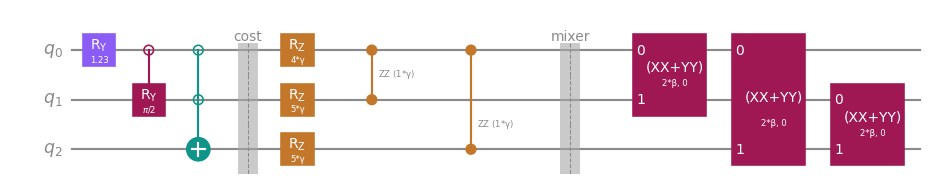

In [16]:
from qiskit.circuit.library import RYGate, XGate, XXPlusYYGate

from resources.helpers import CIRCUIT, show


def w_state(qc, a, b, c):
    """Equal spread over |100>, |010>, |001> on qubits a, b, c."""
    qc.ry(2 * np.arcsin(1 / np.sqrt(3)), a)
    qc.append(RYGate(np.pi / 2).control(1, ctrl_state=0), [a, b])
    qc.append(XGate().control(2, ctrl_state="00"), [a, b, c])


def xy_mixer(qc, beta, cubes):
    for c in range(len(cubes)):
        q = [3 * c, 3 * c + 1, 3 * c + 2]
        for i, j in ((0, 1), (0, 2), (1, 2)):
            qc.append(XXPlusYYGate(2 * beta), [q[i], q[j]])


def constrained_qaoa(H, gammas, betas, cubes=CUBES):
    qc = QuantumCircuit(3 * len(cubes))
    for c in range(len(cubes)):
        w_state(qc, 3 * c, 3 * c + 1, 3 * c + 2)
    for g, b in zip(gammas, betas):
        qc.barrier(label="cost")
        cost_layer(qc, H, g)
        qc.barrier(label="mixer")
        xy_mixer(qc, b, cubes)
    return qc


H_fb = front_back_hamiltonian(CUBES)
print(f"{H_fb.num_qubits} qubits, {len(H_fb)} Pauli terms")
one_cube = constrained_qaoa(front_back_hamiltonian(CUBES[:1]), [gamma], [beta], CUBES[:1])
show(one_cube.draw("mpl", style=CIRCUIT, fold=-1, scale=0.7))

The drawing shows one cube's three qubits for a single round, so it fits on screen. First the W state, then the cost step, then the three XY gates. The real circuit repeats the same blocks for all four cubes and feeds the cost step all of $H$.

Now scan the same grid of angles. The heatmap shows the average cost for each $(\gamma, \beta)$. Dark means low. Predict first: will the best angles land near zero, or somewhere in the middle?

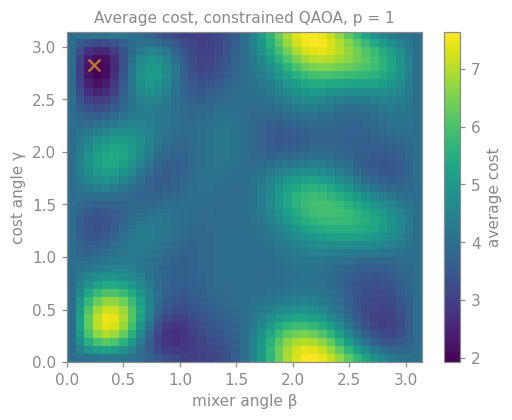

best p=1 angles γ=2.827, β=0.236: average cost 1.93, P(good pick) 18.8% (random valid pick 4.9%)


In [17]:
from resources.helpers import plot_landscape

xy = constrained_qaoa(H_fb, [gamma], [beta])
gammas, betas = np.linspace(0, np.pi, 41), np.linspace(0, np.pi, 41)
avg, hit = scan(xy, H_fb, gammas, betas)
i, j = np.unravel_index(avg.argmin(), avg.shape)
g1, b1 = gammas[i], betas[j]

plot_landscape(avg, gammas, betas, (g1, b1))
print(f"best p=1 angles γ={g1:.3f}, β={b1:.3f}: average cost {avg[i, j]:.2f}, "
      f"P(good pick) {hit[i, j]:.1%} (random valid pick {len(GOOD) / 81:.1%})")

One round already finds a good pick about 1 time in 5, almost four times a random valid pick. The landscape has several valleys, and the cross marks the deepest. A local optimizer started in the wrong valley stops there, which is why a coarse scan comes first.

A second round gives the circuit more freedom. Grids get expensive with four angles, so the next cell hands them to **COBYLA**, a classical optimizer from SciPy that needs no gradients. It starts from the $p = 1$ angles, repeated.

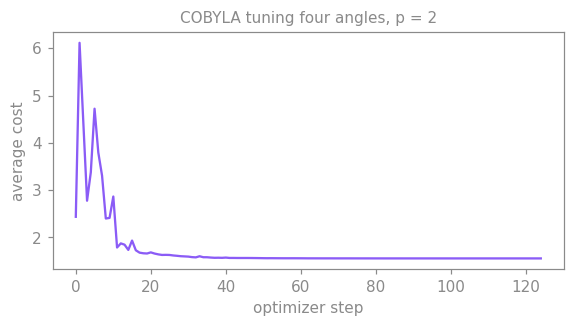

p=2 after 125 evaluations: average cost 1.56, P(good pick) 28.4%


In [18]:
from scipy.optimize import minimize

from resources.helpers import plot_history

costs, wins = diagonal(H_fb), [int(s, 2) for s in GOOD]
history = []


def average_cost(angles):
    p = len(angles) // 2
    probs = Statevector(constrained_qaoa(H_fb, angles[:p], angles[p:])).probabilities()
    history.append(probs @ costs)
    return history[-1]


result = minimize(average_cost, [g1, g1, b1, b1], method="COBYLA", options={"maxiter": 200})
best = result.x
probs = Statevector(constrained_qaoa(H_fb, best[:2], best[2:])).probabilities()

plot_history(history, "COBYLA tuning four angles, p = 2")
print(f"p=2 after {len(history)} evaluations: average cost {result.fun:.2f}, "
      f"P(good pick) {probs[wins].sum():.1%}")

The second round lifts the success rate further. Those numbers are exact probabilities from a statevector. A real run returns **shots**: each shot measures every qubit once and reports one bitstring, so the fraction of good shots wobbles around the exact value.

Now send the tuned circuit to **SV1**, the state-vector simulator AWS runs, through qBraid. This time you write the submission yourself.

Two helpers handle the details:

<ul style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:15px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 13px 0;padding-left:22px;"><li style="margin:0 0 6px 0;"><code>prepare</code> converts the circuit to basic gates, because the W-state and XY gates are not in every device's gate set. It also adds a marker qubit fixed at 1. Providers do not all list bits in the same order, and the marker shows which end holds the last qubit.</li><li style="margin:0 0 6px 0;"><code>strip_marker</code> drops the marker and returns the counts in Qiskit order.</li></ul>

`run_on_qbraid` below joins the steps: prepare the circuit, send it with your `submit_job`, then decode the counts.

In [19]:
from qiskit_aer import AerSimulator

from resources.helpers import prepare, strip_marker


def run_on_qbraid(circuit, shots=1000):
    """Prepare the circuit, send it with your submit_job, return counts in Qiskit order."""
    qc = prepare(circuit)
    raw = submit_job(qc, shots)
    if raw is None:
        print("submit_job returned nothing yet, so this ran on the local Aer simulator.")
        raw = AerSimulator(seed_simulator=SEED).run(qc, shots=shots).result().get_counts()
    return strip_marker(raw)

<div style="background:rgba(128,128,128,0.08);border:1px solid rgba(128,128,128,0.26);border-left:3px solid #8B5CF6;border-radius:10px;padding:18px 22px;margin:18px 0;"><div style="display:flex;align-items:baseline;gap:12px;margin-bottom:9px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:22px;font-weight:500;color:#8B5CF6;line-height:1;">01</span><span style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:400;font-size:17px;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));">Query a device, then submit a job</span></div><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:14.5px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));">Fill in <code>submit_job</code> in the next cell. Create a qBraid provider, get the SV1 device by its id, and print its status before you send anything. Then run the circuit, print the job id, and return the counts.</div></div>

These pages show each step:

- the [native provider guide](https://docs.qbraid.com/v2/sdk/user-guide/providers/native): create a provider, find a device, run a circuit, and read the result,
- the [runtime components guide](https://docs.qbraid.com/v2/sdk/user-guide/runtime/components): what a provider, a device and a job are, and
- `resources/02_qbraid_sdk.ipynb`, sections 2 to 4.

In qBraid Lab your credentials load on their own. A job costs 0.375 credits. Until `submit_job` returns counts, the cell after it runs on the local Aer simulator and says so.

In [20]:
SV1 = "aws:aws:sim:sv1"


def submit_job(qc, shots):
    """Your code: run qc on a qBraid device and return its counts dictionary."""
    # 1. create a provider for your qBraid account
    # 2. get the device with id SV1 and print its status
    # 3. run qc with this many shots, print the job id, and return the counts
    return None

Run the next cell, then open the [quantum jobs page](https://account.qbraid.com/quantum-jobs) to watch your job. Predict first: out of 1,000 shots, roughly how many will be one of the 4 good picks?

submit_job returned nothing yet, so this ran on the local Aer simulator.
282 of 1000 shots are good picks (28.2%); exact value 28.4%


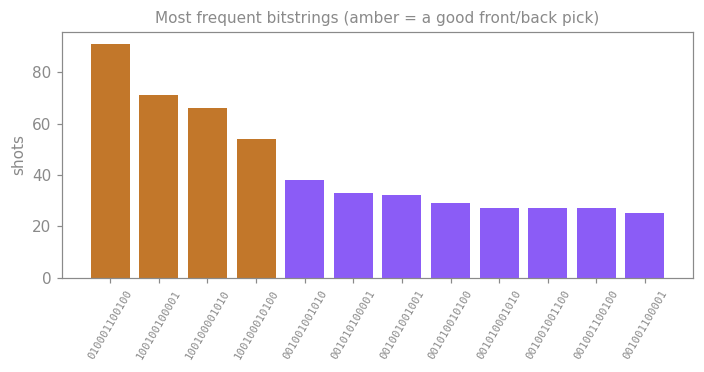

In [21]:
from resources.helpers import plot_top_counts

shots = 1000
counts = run_on_qbraid(constrained_qaoa(H_fb, best[:2], best[2:]), shots=shots)
good = sum(counts.get(s, 0) for s in GOOD)
print(f"{good} of {shots} shots are good picks ({good / shots:.1%}); "
      f"exact value {probs[wins].sum():.1%}")

plot_top_counts(counts, GOOD)

The shot count lands close to the exact probability, as it should on a noise-free simulator. Each amber bar decodes to one pair per cube. Read a bitstring right to left in groups of three: the first group is cube 1, and the position of its 1 is the chosen pair.

<div style="background:rgba(128,128,128,0.08);border:1px solid rgba(128,128,128,0.26);border-left:2px solid #C2772A;border-radius:10px;padding:18px 22px;margin:14px 0;"><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:400;font-size:14px;color:#C2772A;margin-bottom:7px;">What this warm-up shows</div><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:14.5px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));">The same algorithm went from about 1 good pick in 70 to more than 1 in 4, only by changing where it starts and how it mixes. Encoding the rules into the circuit, not into penalties, is the single biggest lever you have in this challenge.</div></div>

<hr style="border:0;border-top:1px solid rgba(128,128,128,0.26);margin:26px 0;">

<div style="display:flex;align-items:center;gap:14px;justify-content:space-between;margin-bottom:10px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:2px;text-transform:uppercase;color:#8B5CF6;">Section 7 · Your challenge</span><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:11px;letter-spacing:1px;color:#8B5CF6;white-space:nowrap;"><svg width="11" height="11" viewBox="0 0 24 24" fill="none" stroke="#8B5CF6" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round" style="vertical-align:-1px;margin-right:5px;"><circle cx="12" cy="12" r="9"/><path d="M12 6.5V12l3.5 2"/></svg>5 min</span></div>

<div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:28px;line-height:1.22;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 10px 0;">What is <span style="color:#8B5CF6;">left for you</span> to solve?</div>

Sections 3 and 6 solved only the front and back. Your challenge is the left and right too: the whole tower, then towers of any size. `GRADING.md` explains how each level is judged.

<div style="background:rgba(128,128,128,0.08);border:1px solid rgba(128,128,128,0.26);border-left:3px solid #8B5CF6;border-radius:10px;padding:18px 22px;margin:18px 0;"><div style="display:flex;align-items:baseline;gap:12px;margin-bottom:9px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:22px;font-weight:500;color:#8B5CF6;line-height:1;">01</span><span style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:400;font-size:17px;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));">Core: the full four-cube puzzle</span></div><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:14.5px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));">Find a solved tower with a quantum algorithm, run on SV1 through qBraid. Report how often your circuit returns a correct tower, how many qubits and two-qubit gates it uses, and what it cost. Then compare with the brute force and with random guessing.</div></div>

<div style="background:rgba(128,128,128,0.08);border:1px solid rgba(128,128,128,0.26);border-left:3px solid #C2772A;border-radius:10px;padding:18px 22px;margin:18px 0;"><div style="display:flex;align-items:baseline;gap:12px;margin-bottom:9px;"><span style="font-family:'JetBrains Mono','SF Mono',Menlo,Consolas,monospace;font-size:22px;font-weight:500;color:#C2772A;line-height:1;">02</span><span style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:400;font-size:17px;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));">Bonus: N cubes and N colours</span></div><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:14.5px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));">Generalize your method to <i>N</i> cubes painted with <i>N</i> colours, where each colour must show once on each side. Run it for every <i>N</i> you can, and show how qubits, depth and success rate grow with <i>N</i>. The cell below makes puzzles with exactly one answer.</div></div>

In [22]:
import random


def make_puzzle(n, seed):
    """N cubes, N colours, a planted answer: two random cycles through all colours."""
    rng = random.Random(seed)
    letters = "".join(chr(ord("A") + i) for i in range(n))
    cycles = []
    for _ in range(2):
        order = rng.sample(letters, n)
        lines = [order[i] + order[(i + 1) % n] for i in range(n)]
        rng.shuffle(lines)
        cycles.append(lines)
    cubes = []
    for i in range(n):
        third = rng.choice(letters) + rng.choice(letters)
        pairs = ["".join(rng.sample(pair, 2)) for pair in (cycles[0][i], cycles[1][i], third)]
        rng.shuffle(pairs)
        cubes.append(pairs)
    return cubes


def count_answers(cubes):
    """How many of the 6**n cases solve the puzzle."""
    letters = sorted({ch for cube in cubes for pair in cube for ch in pair})
    total = 0
    for choice in itertools.product(CHOICES, repeat=len(cubes)):
        for side in (0, 1):
            deg = dict.fromkeys(letters, 0)
            for cube, pick in zip(cubes, choice):
                for ch in cube[pick[side]]:
                    deg[ch] += 1
            if any(d != 2 for d in deg.values()):
                break
        else:
            total += 1
    return total


# seeds checked to give exactly one tower: 2 cases, the tower and its quarter turn
BONUS = {5: 16, 6: 86, 7: 68, 8: 4}
for n, seed in BONUS.items():
    start = time.perf_counter()
    found = count_answers(make_puzzle(n, seed))
    print(f"N={n}: {6 ** n:>9,} cases, {found} solve it, "
          f"{time.perf_counter() - start:.1f} s, one-hot qubits {6 * n}")

N=5:     7,776 cases, 2 solve it, 0.0 s, one-hot qubits 30
N=6:    46,656 cases, 2 solve it, 0.1 s, one-hot qubits 36
N=7:   279,936 cases, 2 solve it, 0.7 s, one-hot qubits 42
N=8: 1,679,616 cases, 2 solve it, 4.7 s, one-hot qubits 48


The brute force grows by a factor of 6 per cube, and the one-hot encoding needs 6 qubits per cube. Both numbers are yours to beat. `make_puzzle` plants an answer, so every puzzle it makes has at least one. The seeds above give exactly one tower, which shows up as 2 cases: the tower and its quarter turn. Check any new seed with `count_answers` before you trust it.

Some directions worth trying:

<ul style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:15px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));margin:0 0 13px 0;padding-left:22px;"><li style="margin:0 0 6px 0;"><b>constrained mixers:</b> extend the W state and XY mixer to the left/right qubits, and stop a pair from serving both axes,</li><li style="margin:0 0 6px 0;"><b>fewer qubits:</b> a cube has only 6 valid choices, which fit in 3 qubits instead of 6,</li><li style="margin:0 0 6px 0;"><b>split the work:</b> sample front/back 2-factors, then pair two that share no line, and explain what stays quantum,</li><li style="margin:0 0 6px 0;"><b>other algorithms:</b> VQE, variational imaginary time evolution, or Grover adaptive search, and</li><li style="margin:0 0 6px 0;"><b>better tuning:</b> CVaR objectives, warm starts, or growing the circuit one layer at a time.</li></ul>

Use AI coding agents if you like, and say how in your submission. `AGENTS.md` tells an agent how to work in this repository.

<div style="background:rgba(128,128,128,0.08);border:1px solid rgba(128,128,128,0.26);border-left:2px solid #0E9488;border-radius:10px;padding:18px 22px;margin:14px 0;"><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:400;font-size:14px;color:#0E9488;margin-bottom:7px;">Credits for real quantum hardware</div><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:14.5px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));">Running on a real quantum device is optional, and a QPU job costs far more than an SV1 job. If your team needs more credits to run your solution on real quantum hardware, get in touch with the organizers. They will give you extra credits.</div></div>

<div style="background:rgba(128,128,128,0.08);border:1px solid rgba(128,128,128,0.26);border-left:2px solid #8B5CF6;border-radius:10px;padding:18px 22px;margin:14px 0;"><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:400;font-size:14px;color:#8B5CF6;margin-bottom:7px;">Credit</div><div style="font-family:'Space Grotesk',-apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;font-weight:300;font-size:14.5px;line-height:1.65;color:var(--text-primary-clr1, var(--jp-content-font-color1, #ECE9E0));">The idea of solving Instant Insanity on a quantum computer comes from the IonQ challenge at SC Quantathon v2 (2025), <a href="https://github.com/ionq-samples/SCQuantathon-v2" style="color:#8B5CF6;">ionq-samples/SCQuantathon-v2</a>. This notebook is new code written for Qiskit Fall Fest Connecticut 2026.</div></div>